# Análisis de las emisiones de CO₂ en Colombia mediante regresión lineal

## 1. Introducción
El dióxido de carbono (CO₂) es uno de los principales gases de efecto invernadero relacionados con el cambio climático. Sus emisiones provienen principalmente de actividades humanas como el consumo de combustibles fósiles, la generación de energía, el transporte y diversos procesos industriales. Por esta razón, el análisis de las emisiones de CO₂ permite comprender su evolución histórica e identificar tendencias relevantes para el estudio de los desafíos ambientales.

En este proyecto se analizarán las emisiones anuales de CO₂ de Colombia utilizando información publicada por la plataforma Our World in Data. Esta plataforma recopila, organiza y presenta datos estadísticos sobre diferentes fenómenos globales, con el propósito de facilitar el acceso a información basada en evidencia.

El proyecto incluye la descarga y selección de los datos correspondientes a Colombia, la limpieza y organización de la información, la elaboración de visualizaciones y la aplicación de un modelo de regresión lineal. El modelo permitirá estudiar la relación entre el año y las emisiones anuales de CO₂, así como identificar una tendencia general en el período analizado. Finalmente, se interpretarán los resultados y se señalarán las limitaciones del modelo utilizado.

## 2. Planteamiento del problema

Las emisiones de dióxido de carbono constituyen un asunto relevante en el estudio del cambio climático, debido a que la acumulación de este gas en la atmósfera está relacionada con el aumento de la temperatura global y con diversas alteraciones ambientales. Colombia también genera emisiones de CO₂ como consecuencia de actividades relacionadas con el transporte, la producción de energía, la industria y el consumo de combustibles fósiles.

Aunque existen registros históricos sobre las emisiones de CO₂, estos datos deben ser organizados y analizados para comprender adecuadamente su comportamiento a lo largo del tiempo. La observación directa de los valores numéricos puede dificultar la identificación de tendencias, variaciones y cambios significativos. En este contexto, las herramientas de análisis de datos y las visualizaciones permiten presentar la información de manera más clara y facilitar su interpretación.

Por lo anterior, se propone analizar las emisiones anuales de CO₂ de Colombia mediante técnicas de limpieza de datos, visualización y regresión lineal. El propósito es establecer cómo han evolucionado las emisiones durante los años disponibles y evaluar en qué medida una tendencia lineal puede representar su comportamiento histórico.

**Pregunta de investigación:**

¿Cómo ha sido el comportamiento de las emisiones anuales de CO₂ en Colombia a lo largo del tiempo y qué tendencia permite identificar un modelo de regresión lineal?

## 3. Objetivos

### 3.1. Objetivo general

Analizar el comportamiento histórico de las emisiones de dióxido de carbono (CO₂) en Colombia mediante el procesamiento y la visualización de datos, así como la aplicación de un modelo de regresión lineal que permita identificar su tendencia a través del tiempo.

### 3.2. Objetivos específicos

- Organizar y limpiar los datos de emisiones de CO₂ de Colombia, identificando registros incompletos, duplicados y variables necesarias para el análisis.

- Representar gráficamente el comportamiento de las emisiones a lo largo de los años, con el fin de identificar tendencias, variaciones y patrones en los datos.

- Aplicar un modelo de regresión lineal y evaluar sus resultados mediante métricas estadísticas, para interpretar la tendencia de las emisiones y las limitaciones del modelo.

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

os.listdir('/content/drive/MyDrive')

['Colab Notebooks',
 'REPORTE ENTREGAS MUÑOZ ING  14 DE SEPTIEMBRE.gsheet',
 'Matrices .gsheet',
 'visita de campo geologia uniagraria.gdoc',
 'z086006694200426e810e657.zip',
 'Proyecto_Co2']

In [7]:
carpeta = '/content/drive/MyDrive/Proyecto_Co2'

os.listdir(carpeta)

['annual-co2-emissions-per-country.csv']

In [8]:
import glob

archivos_csv = glob.glob(carpeta + '/*.csv')

print(archivos_csv)

['/content/drive/MyDrive/Proyecto_Co2/annual-co2-emissions-per-country.csv']


In [14]:
import pandas as pd

In [16]:
import pandas as pd
import glob

carpeta = '/content/drive/MyDrive/Proyecto_Co2'

archivos_csv = glob.glob(carpeta + '/*.csv')

df = pd.read_csv(archivos_csv[0])

df.head()

,Entity,Code,Year,Annual CO₂ emissions
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,80608.0
2,Afghanistan,AFG,1951,87936.0
3,Afghanistan,AFG,1952,87936.0
4,Afghanistan,AFG,1953,98928.0


In [17]:
df.columns

Index(['Entity', 'Code', 'Year', 'Annual CO₂ emissions'], dtype='object')

In [18]:
df_colombia = df[df['Entity'] == 'Colombia'].copy()

df_colombia.head()

,Entity,Code,Year,Annual CO₂ emissions
5879,Colombia,COL,1856,9721.0
5880,Colombia,COL,1857,18205.0
5881,Colombia,COL,1858,20021.0
5882,Colombia,COL,1859,5276.0
5883,Colombia,COL,1860,9308.0


In [19]:
df_colombia.shape

(170, 4)

In [20]:
print("Año inicial:", df_colombia['Year'].min())
print("Año final:", df_colombia['Year'].max())

Año inicial: 1856
Año final: 2025


In [21]:
df_colombia.isnull().sum()

,0
Entity,0
Code,0
Year,0
Annual CO₂ emissions,0


**Verificación de datos faltantes**

Durante la revisión de la información se verificó la presencia de valores faltantes en las variables del conjunto de datos correspondiente a Colombia. Los resultados mostraron que ninguna de las cuatro columnas presenta datos nulos, por lo que los 170 registros cuentan con información completa. En consecuencia, no fue necesario eliminar observaciones por ausencia de datos, permitiendo conservar la totalidad de los registros para las siguientes etapas del análisis.

In [22]:
df_colombia.duplicated().sum()

np.int64(0)

**Verificación de registros duplicados**

Se realizó una revisión de los registros duplicados en el conjunto de datos filtrado para Colombia, con el propósito de identificar posibles repeticiones de información que pudieran afectar el análisis. El resultado fue de cero registros duplicados, por lo que se determinó que no era necesario eliminar filas por esta condición. De esta manera, se conservaron las 170 observaciones disponibles.

In [23]:
df_colombia.dtypes

,0
Entity,object
Code,object
Year,int64
Annual CO₂ emissions,float64


**Verificación de los tipos de datos**

Se revisaron los tipos de datos de las variables que conforman el conjunto de información. Se identificó que las columnas Entity y Code corresponden a datos de tipo objeto, mientras que Year se encuentra almacenada como número entero y Annual CO₂ emissions como número decimal. Esta estructura es adecuada para el análisis, ya que permite realizar operaciones estadísticas sobre los años y los valores de emisiones, sin requerir conversiones adicionales en esta etapa.

In [24]:
df_colombia['Annual CO₂ emissions'].describe()

,Annual CO₂ emissions
count,1.700000e+02
mean,2.328111e+07
std,3.128409e+07
min,5.276000e+03
25%,8.158825e+04
50%,4.112398e+06
75%,4.634790e+07
max,1.062884e+08


Análisis de las estadísticas descriptivas

A partir de las estadísticas descriptivas se identificó que el conjunto de datos cuenta con 170 registros y presenta un promedio de emisiones de CO₂ de aproximadamente 23,28 millones. La mediana fue de 4,11 millones, lo que evidencia una diferencia considerable respecto al promedio y sugiere la presencia de valores elevados en determinados años. Asimismo, la desviación estándar fue de aproximadamente 31,28 millones, indicando una alta variabilidad en los datos. Los valores mínimo y máximo también reflejan una amplia diferencia entre los niveles de emisiones registrados. Estos resultados permiten establecer una primera aproximación al comportamiento de las emisiones en Colombia y justifican la realización de un análisis gráfico para identificar tendencias y variaciones a lo largo del tiempo.

In [26]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

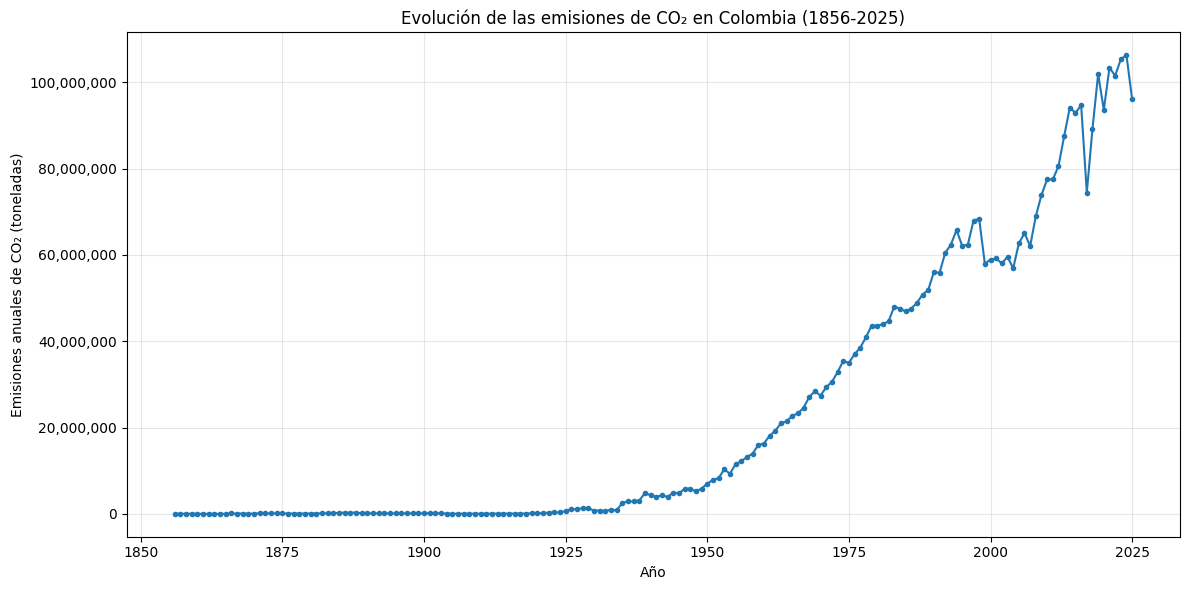

In [27]:
plt.figure(figsize=(12, 6))

plt.plot(
    df_colombia['Year'],
    df_colombia['Annual CO₂ emissions'],
    marker='o',
    markersize=3,
    linewidth=1.5
)

plt.title('Evolución de las emisiones de CO₂ en Colombia (1856-2025)')
plt.xlabel('Año')
plt.ylabel('Emisiones anuales de CO₂ (toneladas)')

plt.gca().yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: f'{x:,.0f}')
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# Calcular la correlación entre el año y las emisiones de CO₂

correlacion = df_colombia['Year'].corr(
    df_colombia['Annual CO₂ emissions']
)

print("Coeficiente de correlación:", correlacion)

Coeficiente de correlación: 0.8752782128104384


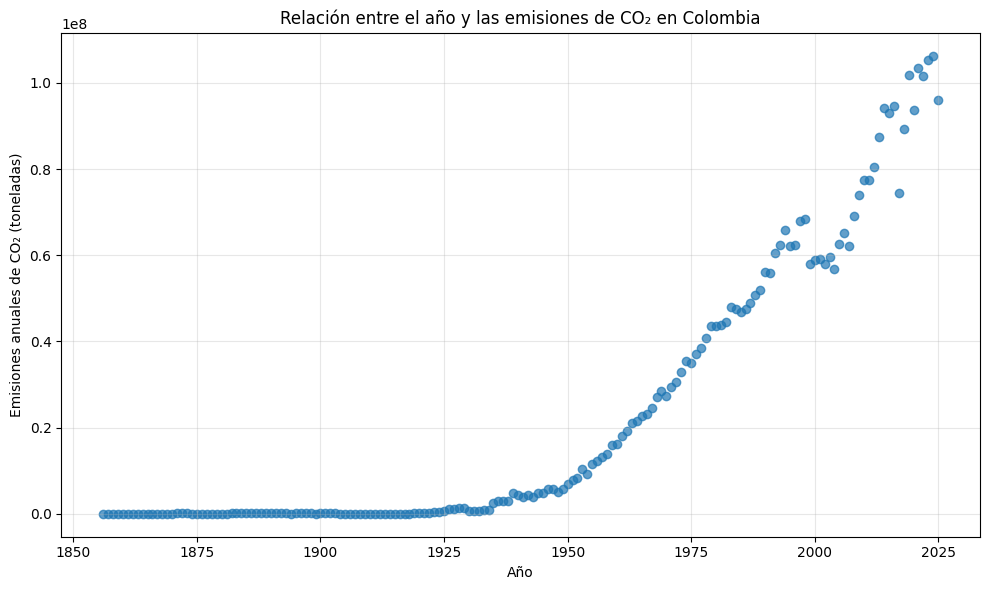

In [29]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_colombia['Year'],
    df_colombia['Annual CO₂ emissions'],
    alpha=0.7
)

plt.title('Relación entre el año y las emisiones de CO₂ en Colombia')
plt.xlabel('Año')
plt.ylabel('Emisiones anuales de CO₂ (toneladas)')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

##Análisis de correlación

El coeficiente de correlación de Pearson obtenido fue de 0,8753, lo que evidencia una relación positiva fuerte entre el año y las emisiones anuales de dióxido de carbono en Colombia. Este resultado indica que, durante el periodo analizado, las emisiones han presentado una tendencia general creciente a medida que transcurre el tiempo. La correlación encontrada permite identificar una asociación lineal importante entre las variables y justifica continuar con la aplicación de un modelo de regresión lineal para estudiar el comportamiento histórico de las emisiones.

In [30]:
from sklearn.linear_model import LinearRegression

# Definir variables independiente y dependiente
X = df_colombia[['Year']]
y = df_colombia['Annual CO₂ emissions']

# Crear y ajustar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Obtener resultados
pendiente = modelo.coef_[0]
intercepto = modelo.intercept_
r2 = modelo.score(X, y)

print("Pendiente:", pendiente)
print("Intercepto:", intercepto)
print("Coeficiente de determinación R²:", r2)

Pendiente: 556336.7367927895
Intercepto: -1056290323.0879374
Coeficiente de determinación R²: 0.7661119498206352


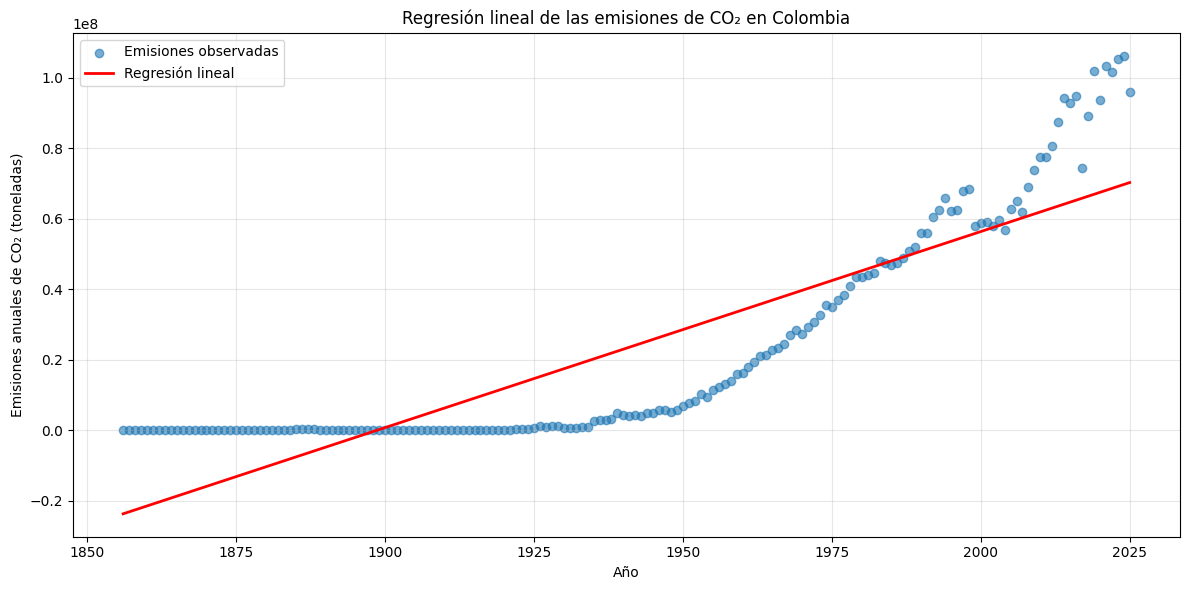

In [31]:
plt.figure(figsize=(12, 6))

plt.scatter(
    X['Year'],
    y,
    label='Emisiones observadas',
    alpha=0.6
)

plt.plot(
    X['Year'],
    modelo.predict(X),
    color='red',
    linewidth=2,
    label='Regresión lineal'
)

plt.title('Regresión lineal de las emisiones de CO₂ en Colombia')
plt.xlabel('Año')
plt.ylabel('Emisiones anuales de CO₂ (toneladas)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

##Análisis de resultados

A partir de la aplicación del modelo de regresión lineal se obtuvo una pendiente de 556.336,74 y un coeficiente de determinación (R²) de 0,7661. La pendiente positiva evidencia una tendencia creciente de las emisiones de CO₂ en Colombia durante el periodo estudiado, con un incremento promedio estimado de aproximadamente 556.337 toneladas anuales.

Por otra parte, el coeficiente de determinación indica que el modelo explica el 76,61 % de la variabilidad de las emisiones a partir del año, lo que representa una capacidad explicativa importante. Sin embargo, el porcentaje restante evidencia que existen fluctuaciones que no pueden ser representadas completamente mediante una relación lineal.

##Ecuación del modelo

* Y=556336.74X - 1056290323.0879    




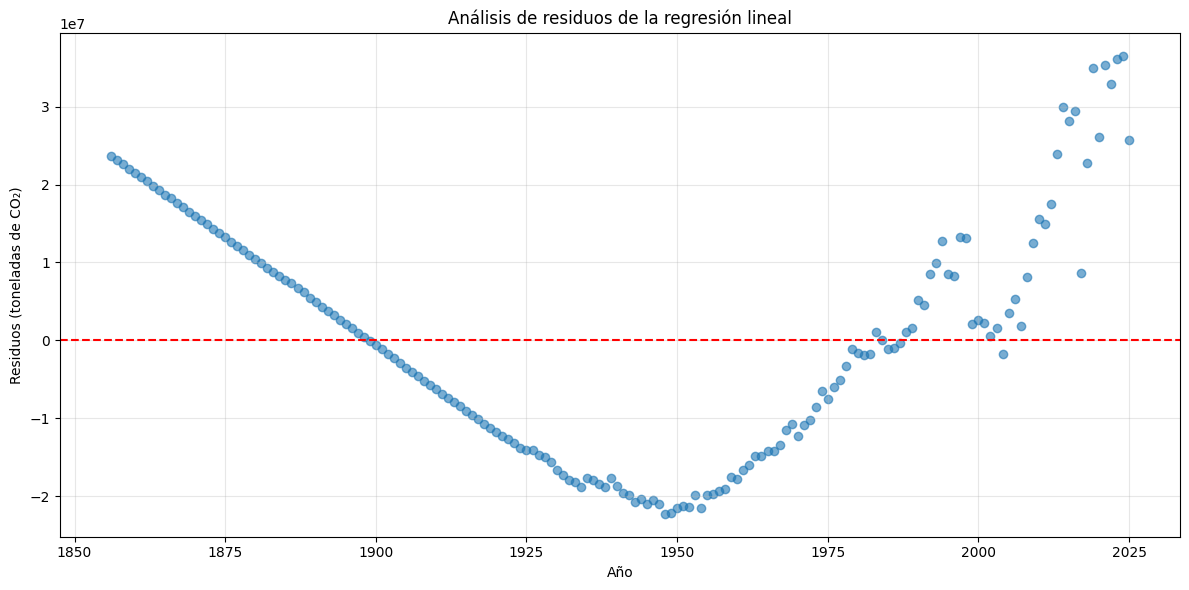

In [32]:
# Calcular valores estimados y residuos

df_colombia['Emisiones_estimadas'] = modelo.predict(X)

df_colombia['Residuos'] = (
    df_colombia['Annual CO₂ emissions']
    - df_colombia['Emisiones_estimadas']
)

# Gráfico de residuos
plt.figure(figsize=(12, 6))

plt.scatter(
    df_colombia['Year'],
    df_colombia['Residuos'],
    alpha=0.6
)

plt.axhline(y=0, color='red', linestyle='--')

plt.title('Análisis de residuos de la regresión lineal')
plt.xlabel('Año')
plt.ylabel('Residuos (toneladas de CO₂)')
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [33]:
# Estadísticas de los residuos

print("Media de los residuos:",
      df_colombia['Residuos'].mean())

print("Desviación estándar de los residuos:",
      df_colombia['Residuos'].std())

print("Residuo mínimo:",
      df_colombia['Residuos'].min())

print("Residuo máximo:",
      df_colombia['Residuos'].max())

print("Primeros 10 residuos:")
print(df_colombia[['Year', 'Residuos']].head(10))

Media de los residuos: -1.567251542035271e-07
Desviación estándar de los residuos: 15129602.923385821
Residuo mínimo: -22275746.18441677
Residuo máximo: 36553137.81933141
Primeros 10 residuos:
      Year      Residuos
5879  1856  2.373906e+07
5880  1857  2.319121e+07
5881  1858  2.263669e+07
5882  1859  2.206561e+07
5883  1860  2.151330e+07
5884  1861  2.095985e+07
5885  1862  2.041892e+07
5886  1863  1.985936e+07
5887  1864  1.929807e+07
5888  1865  1.873233e+07


##Análisis de residuos del modelo

El análisis de los residuos permitió identificar una media aproximada de cero, resultado esperado en un modelo de regresión lineal estimado mediante mínimos cuadrados. Sin embargo, la desviación estándar de 15.129.602,92 toneladas evidencia una dispersión considerable entre los valores observados y los estimados. Asimismo, se identificaron residuos comprendidos entre -22.275.746,18 y 36.553.137,82 toneladas, lo que refleja diferencias importantes en la capacidad predictiva del modelo a lo largo del periodo estudiado. Estos resultados sugieren que, aunque la regresión lineal permite identificar una tendencia general creciente, no representa completamente las variaciones históricas de las emisiones de CO₂ en Colombia.

In [34]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

# Calcular indicadores de error
mae = mean_absolute_error(y, modelo.predict(X))

rmse = np.sqrt(
    mean_squared_error(y, modelo.predict(X))
)

print("Error absoluto medio (MAE):", mae)
print("Raíz del error cuadrático medio (RMSE):", rmse)

Error absoluto medio (MAE): 12572913.34545847
Raíz del error cuadrático medio (RMSE): 15085038.458619671


In [35]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

# Crear modelo polinómico de grado 2
modelo_polinomico = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

# Ajustar modelo
modelo_polinomico.fit(X, y)

# Realizar predicciones
y_pred_poly = modelo_polinomico.predict(X)

# Calcular indicadores
r2_poly = r2_score(y, y_pred_poly)
mae_poly = mean_absolute_error(y, y_pred_poly)
rmse_poly = np.sqrt(mean_squared_error(y, y_pred_poly))

print("R² polinómico:", r2_poly)
print("MAE polinómico:", mae_poly)
print("RMSE polinómico:", rmse_poly)

R² polinómico: 0.9787635625779951
MAE polinómico: 3771337.660823359
RMSE polinómico: 4545516.474695608
